In [1]:
from __future__ import division, unicode_literals, print_function  # for compatibility with Python 2 and 3

import matplotlib as mpl
import matplotlib.pyplot as plt

# change the following to %matplotlib notebook for interactive plotting
%matplotlib inline

# Optionally, tweak styles.
mpl.rc('figure',  figsize=(10, 5))
mpl.rc('image', cmap='gray')

In [2]:
import numpy as np
import pandas as pd
from pandas import DataFrame, Series  # for convenience

import pims
import trackpy as tp

In [3]:
collagen = 4 # can be 2 or 4
day = 1 # can be 0 or 1
section = 1 # can be 1 or 2

path = f'202505_{collagen}/D{day}/s{section}'

condition_id = (collagen,day,section)

In [4]:
#### PARAMETERS
# for feature detection
size = 17
mass = 1000
# for trajectory detection
pixels_movement = 15
steps_memory = 2
# trajectory filtering
length_traj_filter = 5

In [5]:
@pims.pipeline
def gray(image):
    return image[:, :, 1]  # Take just the green channel

frames = gray(pims.open('D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/'+path+'/processed_frames/recortada*.png'))

In [6]:
frames

(ImageSequence,) processed through proc_func. Original repr:
    <Frames>
    Source: D:\OneDrive - unizar.es\I3A\MPA_JAJ\1_DATA\GBM_IMMUNE\PBMC_videos\may2025\202505_4\D1\s1\processed_frames\recortada*.png
    Length: 44 frames
    Frame Shape: (410, 940, 3)
    Pixel Datatype: uint8

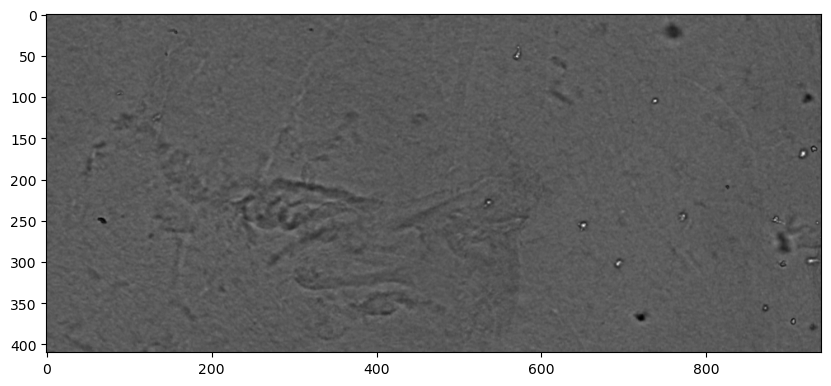

In [7]:
plt.imshow(frames[10]);

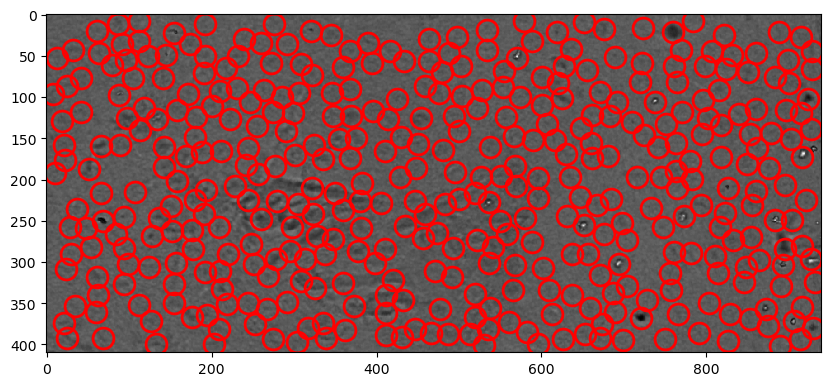

In [8]:
f = tp.locate(frames[10], size, invert=True)
f.head()
tp.annotate(f, frames[10]);

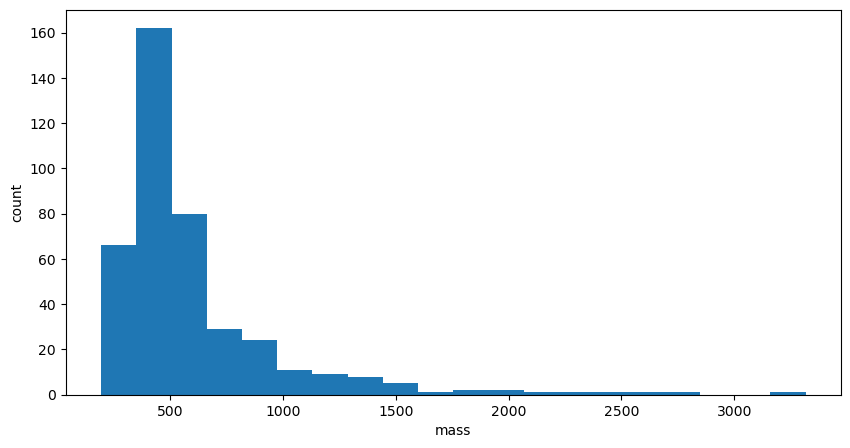

In [9]:
fig, ax = plt.subplots()
ax.hist(f['mass'], bins=20)

# Optionally, label the axes.
ax.set(xlabel='mass', ylabel='count');

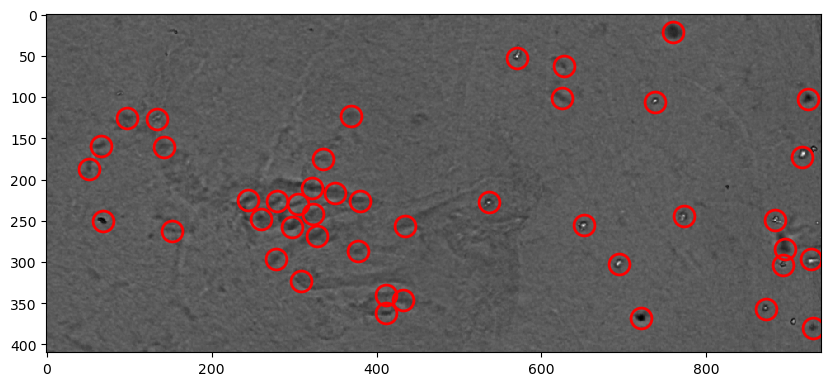

In [10]:
f = tp.locate(frames[10], size, minmass=mass, invert=True)
f.head()
tp.annotate(f, frames[10]);

In [11]:
#locate features in all frames
f = tp.batch(frames, size, minmass=mass, invert=False);

Frame 43: 27 features


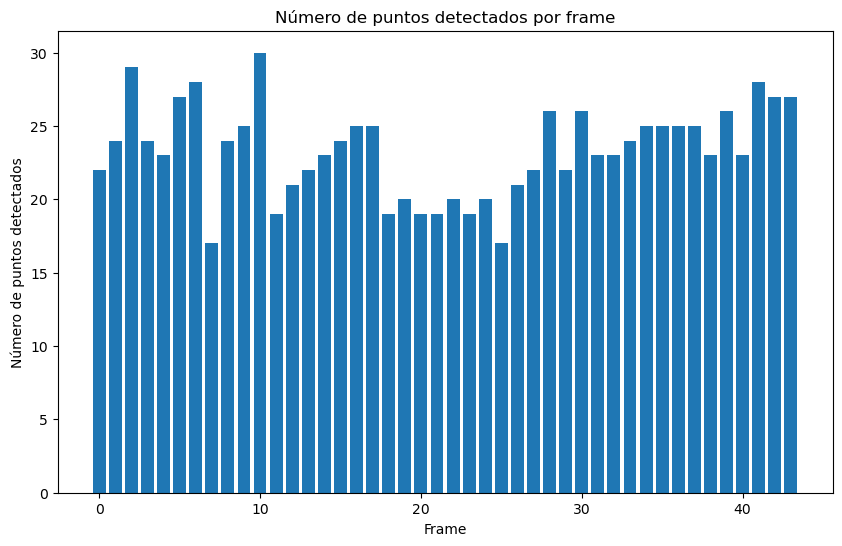

In [12]:
# Contar el número de puntos detectados por frame
puntos_por_frame = f.groupby('frame').size()

# Crear el gráfico de barras
plt.figure(figsize=(10, 6))
plt.bar(puntos_por_frame.index, puntos_por_frame.values)

# Añadir etiquetas y título
plt.xlabel('Frame')
plt.ylabel('Número de puntos detectados')
plt.title('Número de puntos detectados por frame')

# Mostrar el gráfico
plt.show()

In [13]:
@tp.predict.predictor
def predict(t1, particle):
    # This is supposed to be close to the velocity in fakeframe().
    # Note that the default order for coordinates in trackpy is (y, x).
    # You will rarely have to know this unless you are doing something
    # nerdy like making your own predictor.
    velocity = np.array((3, 0))  # (v_y, v_x)
    return particle.pos + velocity * (t1 - particle.t)

In [14]:
t = tp.link(f, pixels_movement, memory=steps_memory)

Frame 43: 27 trajectories present.


In [15]:
t2 = tp.filter_stubs(t, length_traj_filter)
# Compare the number of particles in the unfiltered and filtered data.
print('Before:', t['particle'].nunique())
print('After:', t2['particle'].nunique())

Before: 106
After: 42


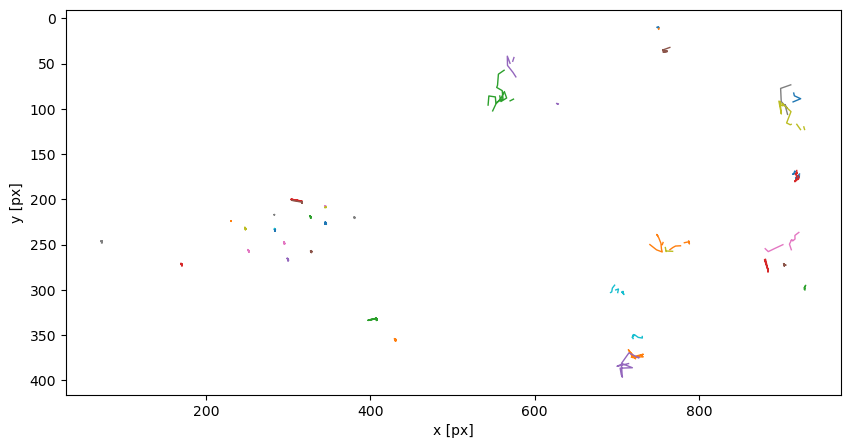

In [16]:
plt.figure()
tp.plot_traj(t2);

In [17]:
# data to matlab 
import pandas as pd
# Asume que 't2' es tu DataFrame de trayectorias de trackpy

# Define la ruta de salida para el archivo CSV
output_csv_path = 'D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/'+path+'/processed_frames/trayectorias_trackpy.csv'

# Exporta el DataFrame completo a CSV
# index=False evita exportar el índice de filas de Pandas, que no es útil en MATLAB
t2.to_csv(output_csv_path, index=False)

print(f"DataFrame exportado a: {output_csv_path}")

DataFrame exportado a: D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/202505_4/D1/s1/processed_frames/trayectorias_trackpy.csv
